In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def plot_confusion_matrix( ax, cm, labels, title, cmap=None,cbar=False,shrink=None):
    hm = sns.heatmap(cm,annot=True,fmt='.2f',cmap=cmap,vmin=0,vmax=1,xticklabels=labels,yticklabels=labels,ax=ax,cbar=cbar,square=True)
    ax.set_xlabel('Predicted\n'+title)
    ax.set_ylabel('True')
    if shrink is not None:
        pos = ax.get_position()
        ax.set_position([
            pos.x0 + (pos.width - pos.width * shrink) / 2 ,
            pos.y0 + (pos.height - pos.height * shrink) / 2,
            pos.width * shrink,pos.height * shrink])
    return hm

In [3]:
cm2 = np.load("multi/acc/comb/cm2_10flod.npy", allow_pickle=True).item()
cm4 = np.load("multi/acc/comb/cm4_10flod.npy", allow_pickle=True).item()
cm2_csub = np.load("multi/acc/comb/cm2_csub_10flod.npy", allow_pickle=True).item()
cm4_csub = np.load("multi/acc/comb/cm4_csub_10flod.npy", allow_pickle=True).item()

/tmp/ipykernel_1126254/2525542967.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


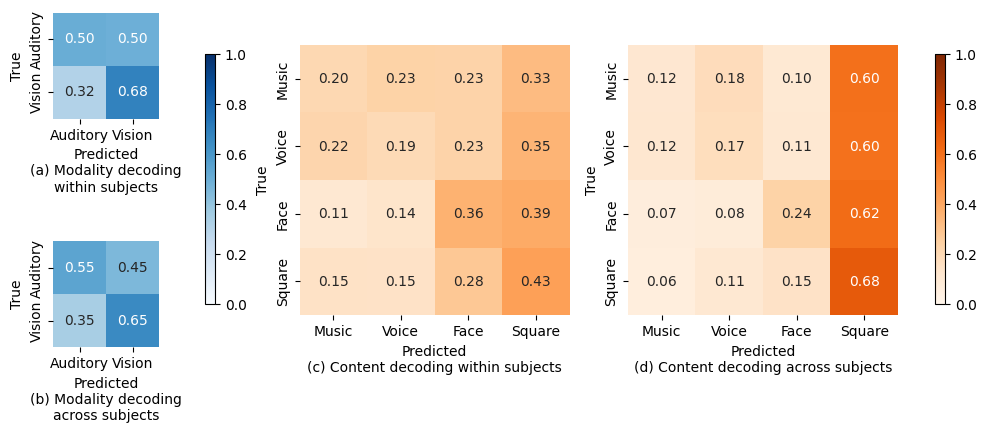

In [4]:
fig = plt.figure(figsize=(10, 5))
ax_2w = plt.subplot2grid((2, 12), (0, 0), colspan=2)          # 第一行第一列
ax_2c = plt.subplot2grid((2, 12), (1, 0), colspan=2)          # 第二行第一列
ax_4w = plt.subplot2grid((2, 12), (0, 3), colspan=4, rowspan=2)  # 第2-3列，两行
ax_4c = plt.subplot2grid((2, 12), (0, 7), colspan=4, rowspan=2)  # 第4-5列，两行
#bar1 = plt.subplot2grid((2, 12), (0, 2), rowspan=2)  # 第6列，两行
#bar2 = plt.subplot2grid((2, 12), (0, 11), rowspan=2)  # 第6列，两行
bar1 = fig.add_axes([0.21, 0.3, 0.01, 0.5])
bar2 = fig.add_axes([0.94, 0.3, 0.01, 0.5])

label2 = ['Auditory', 'Vision']
label4 = [ 'Music', 'Voice', 'Face', 'Square']
plot_confusion_matrix(ax_2w, cm2["xDAWN+LR"].mean(0), label2, '(a) Modality decoding\nwithin subjects', cmap='Blues')#,shrink=0.8)
hm1 = plot_confusion_matrix(ax_2c, cm2_csub["xDAWN+LR"].mean(0), label2, '(b) Modality decoding\nacross subjects', cmap='Blues')#,shrink=0.8)
plot_confusion_matrix(ax_4w, cm4["xDAWN+LR"].mean(0), label4, '(c) Content decoding within subjects', cmap='Oranges')#,shrink=0.9)
hm2 = plot_confusion_matrix(ax_4c, cm4_csub["xDAWN+LR"].mean(0), label4, '(d) Content decoding across subjects', cmap='Oranges')#,shrink=0.9)
#plot_confusion_matrix(ax_vc, cal_confusion_matrix(matrix["vc"]).mean(0), label2, 'VC', cmap='Oranges')#,shrink=0.8)
#plot_confusion_matrix(ax_ac, cal_confusion_matrix(matrix["ac"]).mean(0), label2, 'AC', cmap='Oranges')#,shrink=0.8)

fig.colorbar(hm1.collections[0],cax=bar1)
fig.colorbar(hm2.collections[0],cax=bar2)

plt.tight_layout()
plt.savefig("multi/fig/mt.pdf", bbox_inches="tight")
plt.show()
